# Tea classifier training in Google Colab

This notebook runs the existing project without changing its Python source files. It mounts Google Drive, installs the dependencies, validates the expected dataset location, builds the manifest, creates a preprocessing preview, and trains the grade and region classifiers.

In [ ]:
from google.colab import drive
from pathlib import Path
import os

drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/TeaProject')
PROJECT_ROOT = DRIVE_ROOT / 'Multimodel_chatgpt'
DATA_ROOT = DRIVE_ROOT / 'dataset'
RAW_DATA_ROOT = DATA_ROOT / 'Raw Dataset'

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(f'Project not found at {PROJECT_ROOT}')
if not RAW_DATA_ROOT.exists():
    raise FileNotFoundError(
        f'Raw Dataset not found in {DATA_ROOT}. '
        'Expected: TeaProject/dataset/Raw Dataset'
    )

os.chdir(PROJECT_ROOT)
print(f'Project: {PROJECT_ROOT}')
print(f'Dataset: {RAW_DATA_ROOT}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/TeaProject/Multimodel_chatgpt
Dataset: /content/drive/MyDrive/TeaProject/dataset/Raw Dataset


In [3]:
!pip install -q -r requirements.txt

## Run configuration

Change these values before running the training cells if needed. Tuning is disabled by default because it starts several extra training runs.

In [4]:
MODEL = 'efficientnet'
EPOCHS = 20
BATCH_SIZE = 16
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
RUN_TUNING = False
TUNING_TRIALS = 6
TUNING_EPOCHS = 10
PREVIEW_LIMIT = 24

In [5]:
# Rebuild the manifest from the Drive dataset and print label counts.
!python scripts/build_manifest.py --data-root "$RAW_DATA_ROOT"

Saved 949 images from 90 physical samples to /content/drive/MyDrive/TeaProject/Multimodel_chatgpt/data/manifest.csv

Grade counts:
 grade
BOP     151
BOPF    442
DUST    230
OP      126
Name: count, dtype: int64

Region counts:
 region
DI    376
KA     40
NU    127
RU    162
SB    180
UP     30
UV     34
Name: count, dtype: int64


In [6]:
# Create a visual preprocessing quality check in results/preprocessing_preview.png.
!python scripts/inspect_preprocessing.py --limit $PREVIEW_LIMIT

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Saved /content/drive/MyDrive/TeaProject/Multimodel_chatgpt/results/preprocessing_preview.png


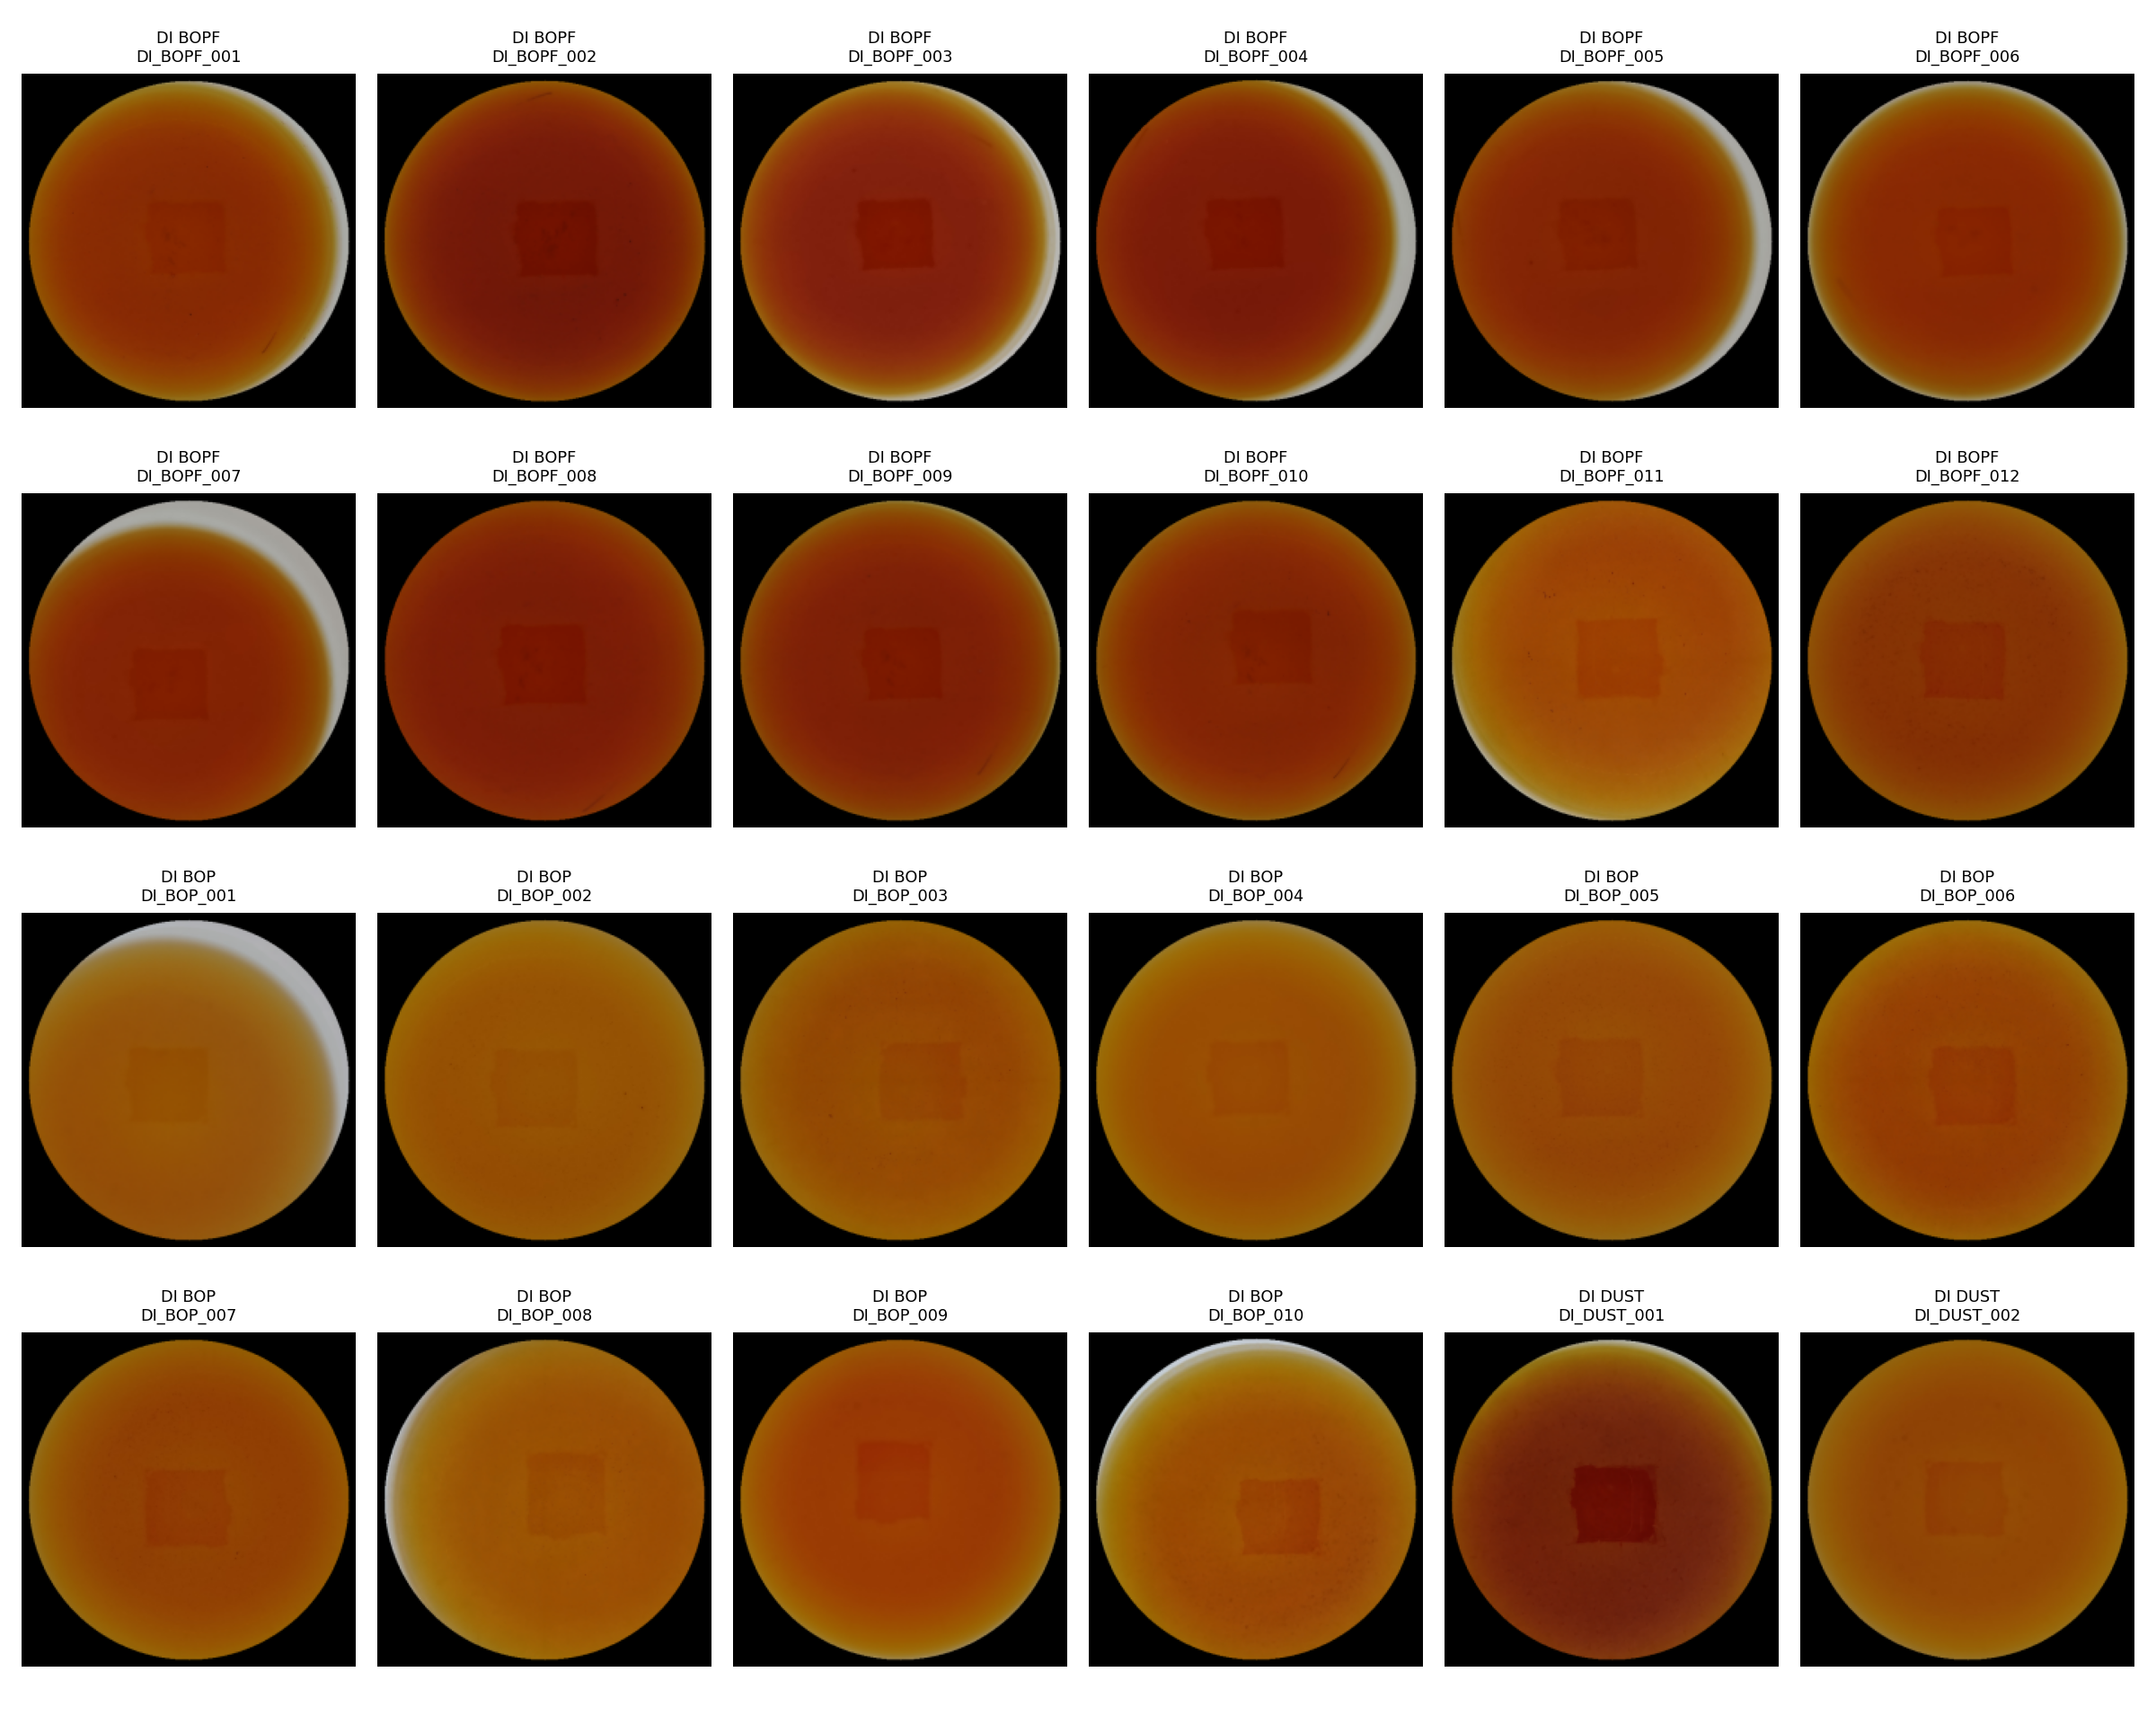

In [7]:
from IPython.display import Image, display
display(Image(filename='results/preprocessing_preview.png'))

## Train the grade classifier

In [8]:
!python scripts/train_grade.py --model $MODEL --epochs $EPOCHS --batch-size $BATCH_SIZE --lr $LEARNING_RATE --weight-decay $WEIGHT_DECAY

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 118MB/s]
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
epoch 01/20: train_acc=0.552, valid_acc=0.519
epoch 02/20: train_acc=0.738, valid_acc=0.538
epoch 03/20: train_acc=0.840, valid_acc=0.608
epoch 04/20: train_acc=0.868, valid_acc=0.509
epoch 05/20: train_acc=0.867, valid_acc=0.453
epoch 06/20: train_acc=0.910, valid_acc=0.500
epoch 07/20: train_acc=0.901, valid_acc=0.561
epoch 08/20: train_acc=0.917, valid_acc=0.571


: 

## Train the region classifier

In [ ]:
!python scripts/train_region.py --model $MODEL --epochs $EPOCHS --batch-size $BATCH_SIZE --lr $LEARNING_RATE --weight-decay $WEIGHT_DECAY

In [ ]:
if RUN_TUNING:
    !python scripts/tune.py --task grade --model $MODEL --trials $TUNING_TRIALS --epochs $TUNING_EPOCHS
    !python scripts/tune.py --task region --model $MODEL --trials $TUNING_TRIALS --epochs $TUNING_EPOCHS
else:
    print('Hyperparameter tuning is disabled. Set RUN_TUNING = True to enable it.')

In [ ]:
# Compare available experiments. This works after baseline training and/or tuning.
!python scripts/compare_experiments.py --task grade
!python scripts/compare_experiments.py --task region

In [ ]:
print(f'All outputs are saved under: {PROJECT_ROOT / "results"}')
print(f'Manifest: {PROJECT_ROOT / "data" / "manifest.csv"}')